# Data Visualization

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Loading the Taxis Dataset :

In [3]:
# Load the 'taxis' dataset 
df = sns.load_dataset("taxis") 
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## Handling Missing Values :

In [4]:
# Check missing values in each column
print(df.isnull().sum())

# Identify columns containing missing values
print("\nColumns with missing values:")
print(df.columns[df.isnull().any()])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [5]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Fill numerical missing values with the median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with the mode
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

In [6]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [7]:
# Remove rows with any remaining missing values
df = df.dropna()

In [8]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

##  Visualizations using Matplotlib/Pandas Plot :

#### Line Chart

In [9]:
df['pickup'] = pd.to_datetime(df['pickup'])

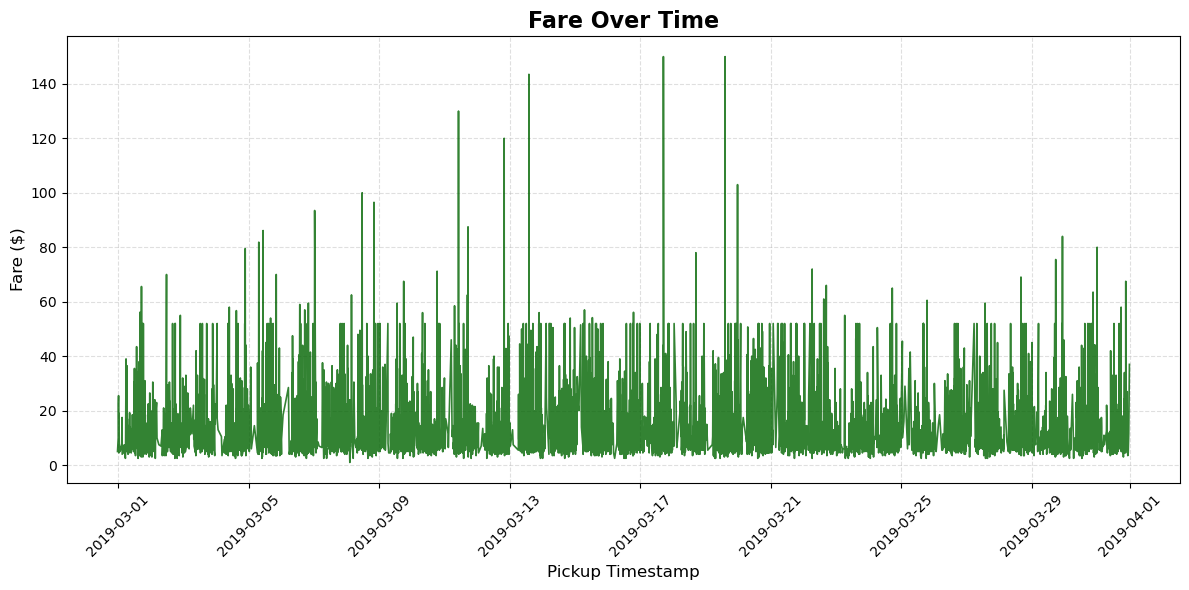

In [10]:
# Sort data by pickup timestamp
df = df.sort_values('pickup')

# Create the line chart
plt.figure(figsize=(12, 6))

plt.plot(df['pickup'], df['fare'],
         color='darkgreen',
         linewidth=1.2,
         alpha=0.8)

# Add title and axis labels
plt.title('Fare Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Pickup Timestamp', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)

# Customize the chart
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

#### Bar Chart

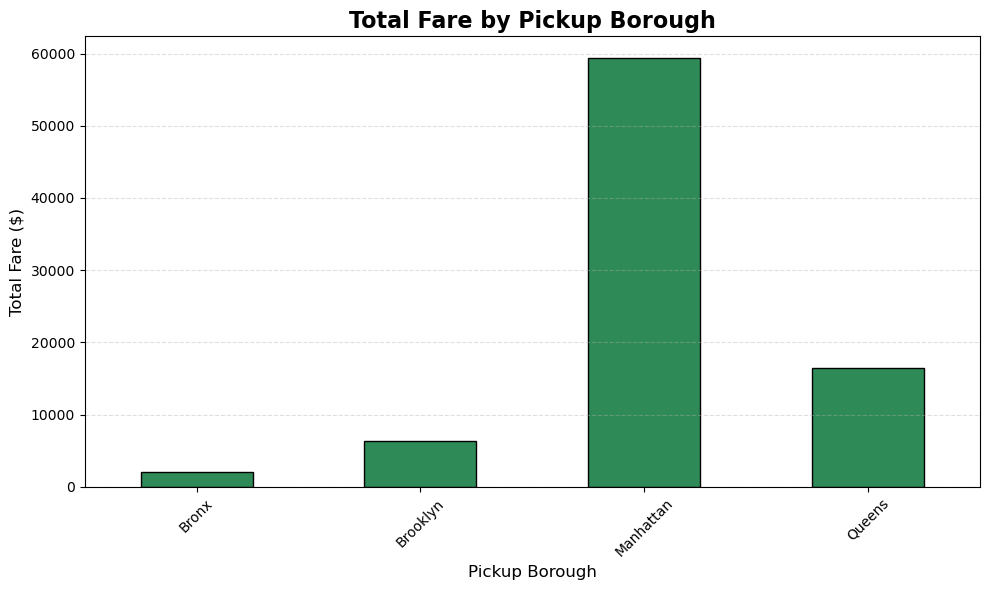

In [11]:
plt.figure(figsize=(10, 6))

df.groupby('pickup_borough')['fare'].sum().plot(
    kind='bar',
    color='seagreen',
    edgecolor='black'
)

plt.title('Total Fare by Pickup Borough', fontsize=16, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Total Fare ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

#### Pie Chart 

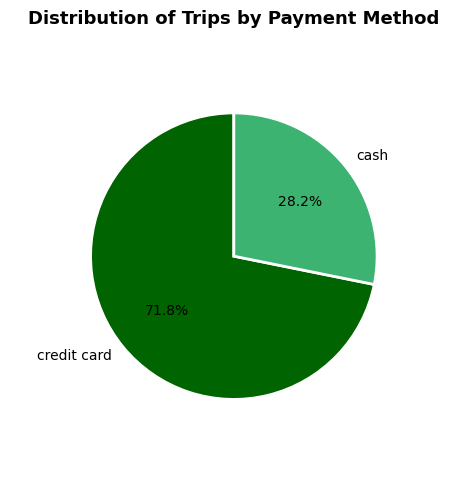

In [12]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(6, 5))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['darkgreen', 'mediumseagreen', 'lightgreen'],
    radius=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title('Distribution of Trips by Payment Method',
          fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

#### Histogram

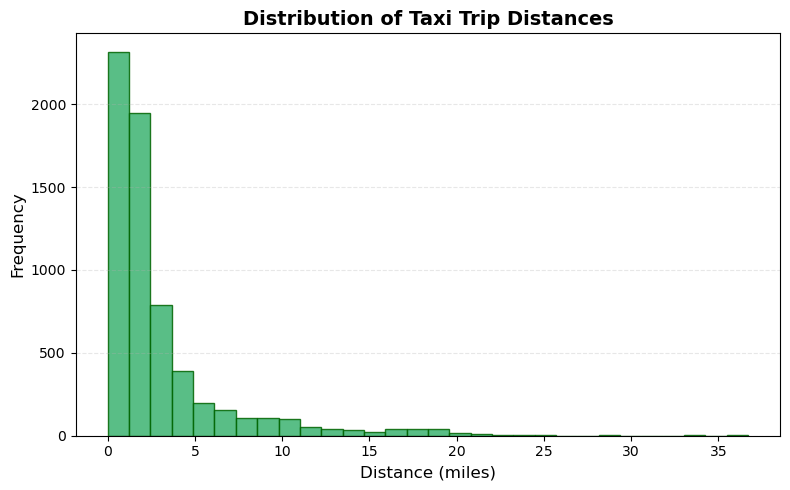

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    df['distance'],
    bins=30,
    color='mediumseagreen',
    edgecolor='darkgreen',
    alpha=0.85
)

plt.title('Distribution of Taxi Trip Distances',
          fontsize=14, fontweight='bold')
plt.xlabel('Distance (miles)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

#### Box Plot  

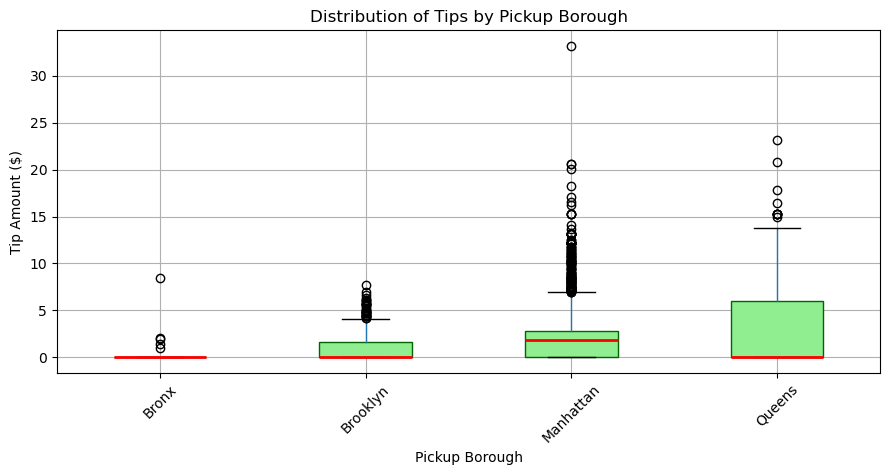

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

df.boxplot(
    column='tip',
    by='pickup_borough',
    ax=ax,
    patch_artist=True,
    boxprops=dict(facecolor='lightgreen', color='darkgreen'),
    medianprops=dict(color='red', linewidth=2)
)

plt.title('Distribution of Tips by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Visualizations using Seaborn :

#### Count Plot  

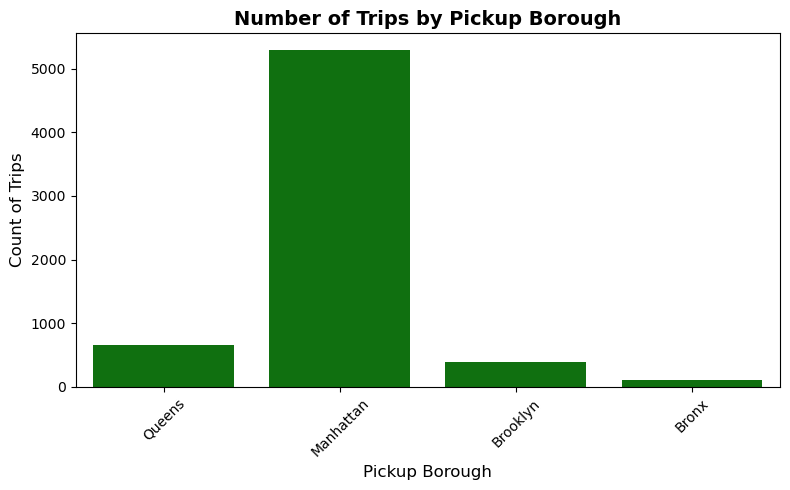

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='pickup_borough',
    color='green'
)

plt.title('Number of Trips by Pickup Borough',
          fontsize=14, fontweight='bold')
plt.xlabel('Pickup Borough', fontsize=12)
plt.ylabel('Count of Trips', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Scatter Plot  

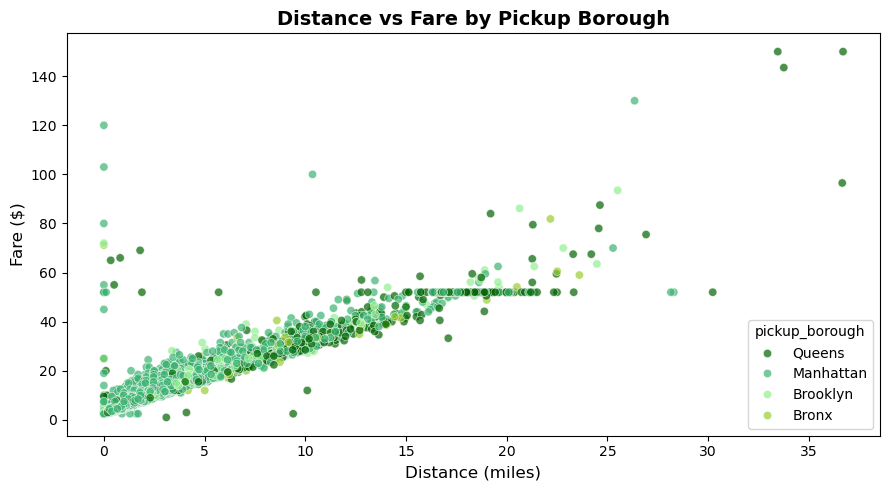

In [16]:
plt.figure(figsize=(9, 5))
green_shades = ['darkgreen', 'mediumseagreen', 'lightgreen', 'yellowgreen']

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough',
    palette=green_shades,
    alpha=0.7
)

plt.title('Distance vs Fare by Pickup Borough',
          fontsize=14, fontweight='bold')
plt.xlabel('Distance (miles)', fontsize=12)
plt.ylabel('Fare ($)', fontsize=12)
plt.tight_layout()
plt.show()

#### Heatmap

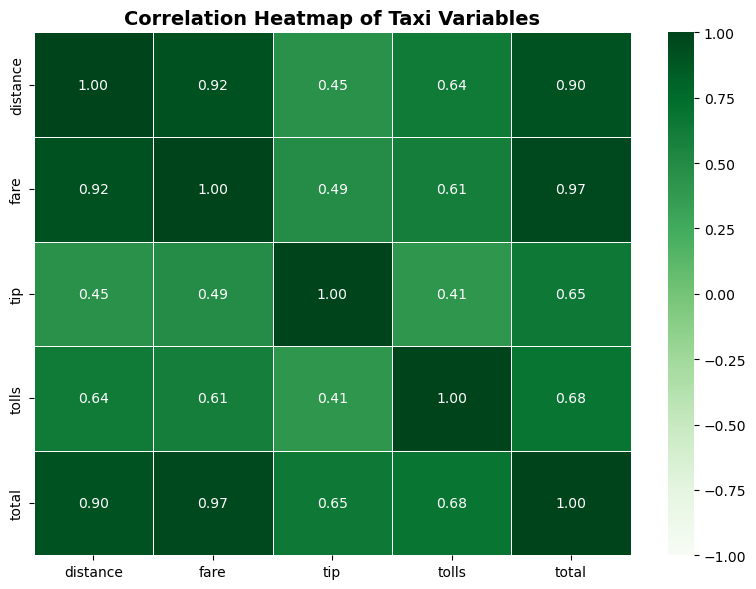

In [17]:
numerical_cols = ['distance', 'fare', 'tip', 'tolls', 'total']

correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='Greens',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Taxi Variables',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Pair Plot  

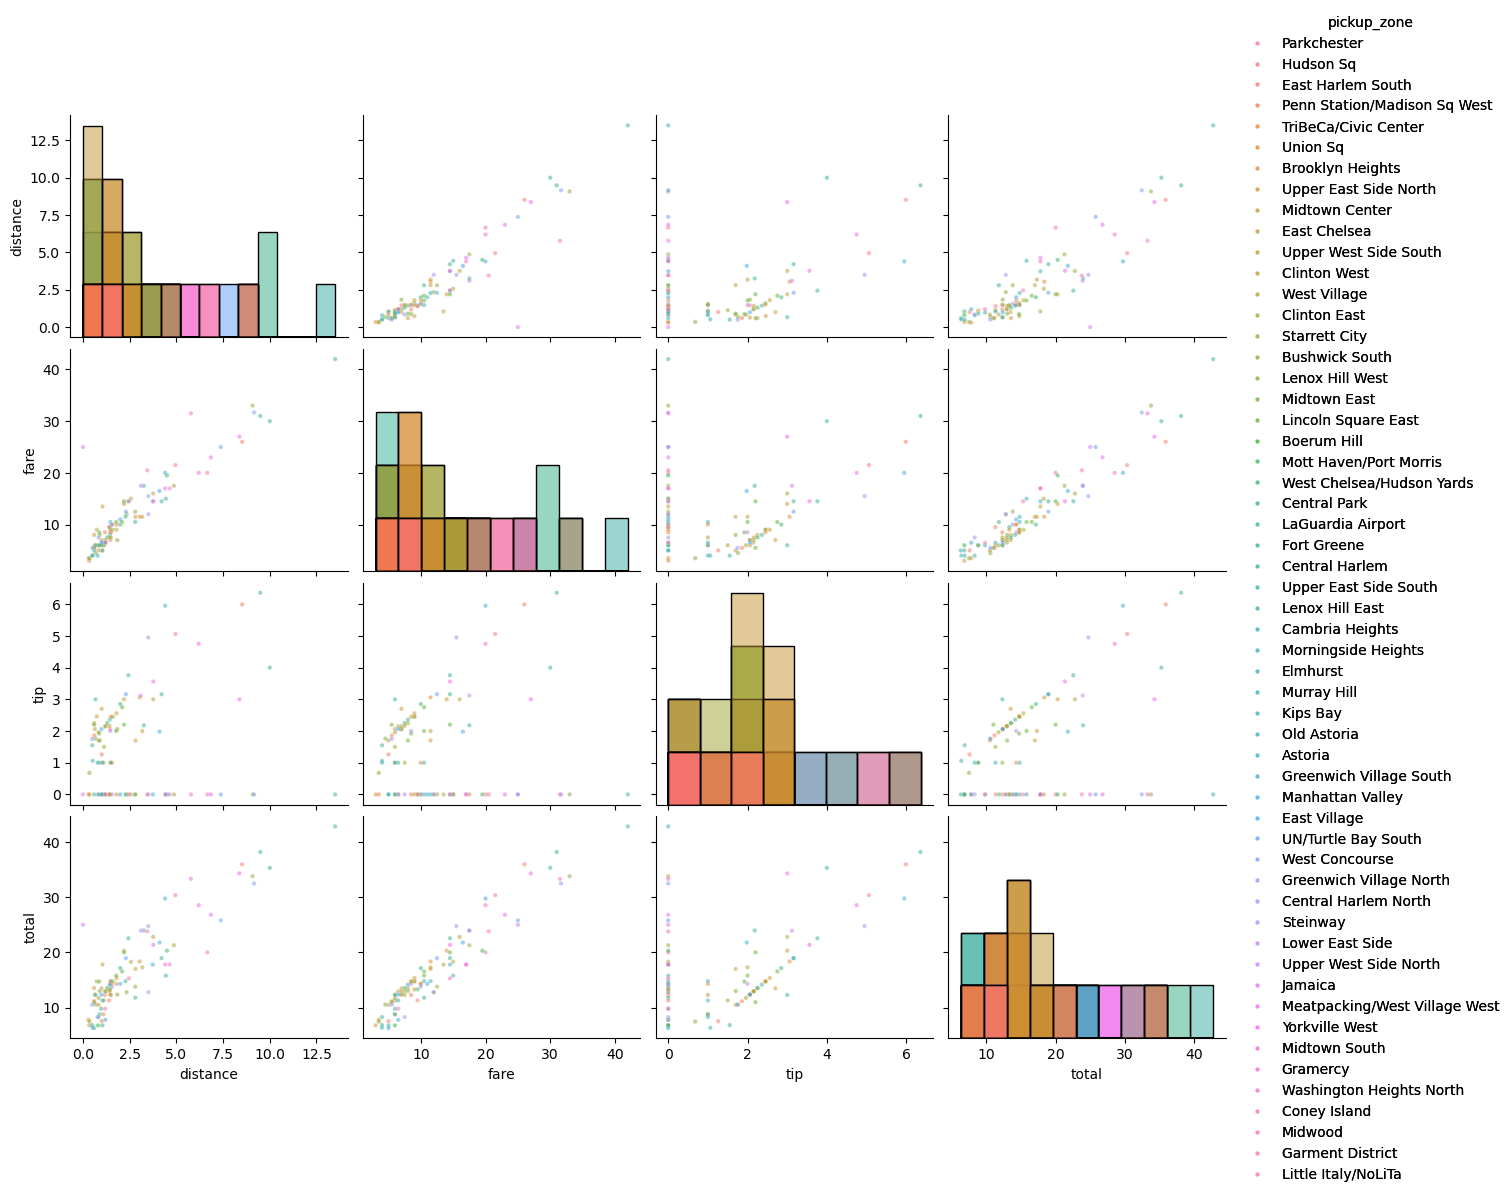

In [18]:
df_sample = df.sample(n=100, random_state=42)

g = sns.pairplot(
    data=df_sample,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    diag_kind='hist',
    plot_kws={'s': 10, 'alpha': 0.5}
)

g.add_legend()
plt.show()

####  Violin Plot  

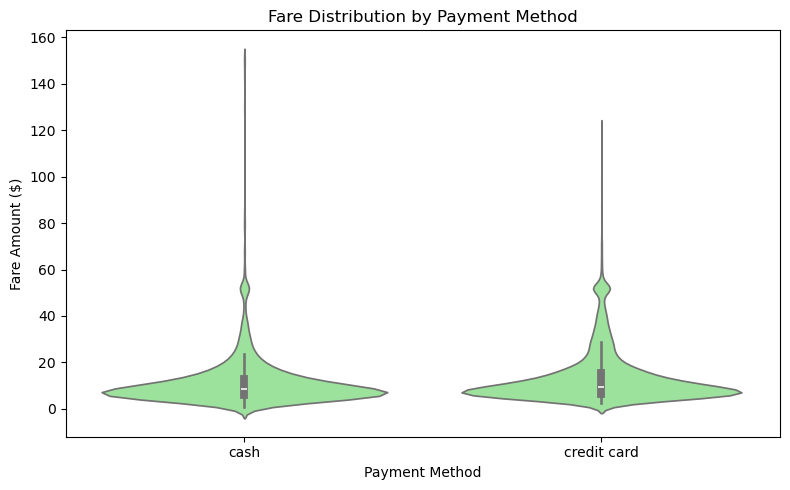

In [19]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    color='lightgreen'
)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare Amount ($)')
plt.tight_layout()
plt.show()